In [1]:
RUN_IDS = [
    "20261029T215235_8e602a1a"
]

CV_IDS = []  # Empty = all available CVs

### 1. Imports and Available run IDs
Works when the notebooks runs from either the project root or evaluation

In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(
    (
        path for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "results").is_dir()
        and (path / "src" / "cv_extraction").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Could not locate the cv-data-extraction project.")

RESULTS_DIR = ROOT / "results"

available_runs = sorted(
    path.name
    for path in RESULTS_DIR.iterdir()
    if path.is_dir() and (path / "config.json").exists()
)

print("Available run IDs:")
print("\n".join(available_runs))

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.25,
})

Available run IDs:
20261029T215235_8e602a1a


### 2. Load attempt and stage timings
Supports both older extraction reports and newer stage-based reports. Incomplete attempts retain their recorded stage timings, but are excluded from successful-duration comparisons.

In [3]:
def read_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))


if not RUN_IDS:
    raise ValueError("Select at least one run ID.")

selected_runs = list(dict.fromkeys(RUN_IDS))
unknown = set(selected_runs) - set(available_runs)

if unknown:
    raise ValueError(f"Unknown run IDs: {sorted(unknown)}")

attempt_rows = []
stage_rows = []
run_rows = []

for run_id in selected_runs:
    run_dir = RESULTS_DIR / run_id
    config = read_json(run_dir / "config.json")

    summary_path = run_dir / "summary.json"
    summary = read_json(summary_path) if summary_path.exists() else {}

    expected_ids = {
        item["id"] for item in config.get("inputs", [])
    }
    if CV_IDS:
        expected_ids &= set(CV_IDS)

    planned = (
        len(expected_ids) * config.get("repetitions", 1)
        if "inputs" in config else None
    )

    start = pd.to_datetime(summary.get("started_at_utc"), utc=True)
    finish = pd.to_datetime(summary.get("finished_at_utc"), utc=True)

    run_rows.append({
        "run_id": run_id,
        "name": config.get("name"),
        "planned_attempts": planned,
        "has_summary": summary_path.exists(),
        "elapsed_seconds": (
            (finish - start).total_seconds()
            if pd.notna(start) and pd.notna(finish) else np.nan
        ),
        "pipeline": " → ".join(
            stage["method"] for stage in config.get("stages", [])
        ),
    })

    for attempt_dir in sorted(
        (run_dir / "documents").glob("*/repeat_*")
    ):
        if not attempt_dir.is_dir():
            continue

        cv_id = attempt_dir.parent.name
        if CV_IDS and cv_id not in CV_IDS:
            continue

        report_path = attempt_dir / "report.json"
        report = read_json(report_path) if report_path.exists() else None

        # Read stages from the attempt report when available.
        # Otherwise recover already-written stage reports.
        stages = report.get("stages", []) if report else [
            read_json(path)
            for path in sorted(attempt_dir.glob("*/report.json"))
        ]

        repetition = int(attempt_dir.name.split("_")[-1])
        metrics = report.get("metrics", {}) if report else {}
        status = report.get("status", "unknown") if report else "incomplete"

        seconds = metrics.get(
            "processing_seconds",
            metrics.get("extraction_seconds"),
        )
        if seconds is None:
            durations = [
                stage.get("metrics", {}).get("duration_seconds")
                for stage in stages
                if stage.get("execution_status") != "skipped"
            ]
            durations = [value for value in durations if value is not None]
            seconds = sum(durations) if durations else np.nan

        attempt_rows.append({
            "run_id": run_id,
            "cv_id": cv_id,
            "repetition": repetition,
            "status": status,
            "seconds": seconds,
            "successful": status in {"completed", "success"},
            "report_present": report is not None,
            "page_count": next(
                (
                    stage.get("metrics", {})["page_count"]
                    for stage in stages
                    if "page_count" in stage.get("metrics", {})
                ),
                metrics.get("page_count"),
            ),
        })

        for stage in stages:
            sm = stage.get("metrics", {})
            stage_rows.append({
                "run_id": run_id,
                "cv_id": cv_id,
                "repetition": repetition,
                "stage": stage.get("name", "unknown"),
                "method": stage.get("method"),
                "execution_status": stage.get("execution_status"),
                "outcome": stage.get("outcome"),
                "attempt_successful": status in {"completed", "success"},
                "seconds": sm.get("duration_seconds"),
                "input_tokens": sm.get("input_tokens"),
                "output_tokens": sm.get("output_tokens"),
                "generation_seconds": sm.get("generation_seconds"),
                "prompt_processing_seconds": sm.get("prompt_processing_seconds"),
                "model_load_seconds": sm.get("model_load_seconds"),
                "error": (stage.get("error") or {}).get("message"),
            })

attempts = pd.DataFrame(attempt_rows, columns=[
    "run_id", "cv_id", "repetition", "status", "seconds",
    "successful", "report_present", "page_count",
])

stages = pd.DataFrame(stage_rows, columns=[
    "run_id", "cv_id", "repetition", "stage", "method",
    "execution_status", "outcome", "attempt_successful", "seconds",
    "input_tokens", "output_tokens", "generation_seconds",
    "prompt_processing_seconds", "model_load_seconds", "error",
])

runs = pd.DataFrame(run_rows).set_index("run_id")

successful = attempts[attempts["successful"]].copy()

print(f"Loaded {len(attempts)} attempts and {len(stages)} stage reports.")
display(runs)

Loaded 170 attempts and 510 stage reports.


,name,planned_attempts,has_summary,elapsed_seconds,pipeline
run_id,,,,,
20261029T215235_8e602a1a,text_baseline,170,True,59860.994675,pdf_text → join_page_text → llm_structuring


### 3. Coverage, failures and timing summary
“Recorded processing” includes failures and the recorded portion of incomplete attempts. Elapsed time is only available for runs with a summary and covers the whole run, even if you filter CVs.

,name,planned_attempts,has_summary,elapsed_seconds,pipeline,status_completed,status_empty_text,status_error,successful_attempts,median_seconds,mean_seconds,fastest_seconds,slowest_seconds,reports_present,missing_attempt_reports,recorded_processing_minutes,whole_run_elapsed_minutes
run_id,,,,,,,,,,,,,,,,,
20261029T215235_8e602a1a,text_baseline,170,True,59860.995,pdf_text → join_page_text → llm_structuring,122,20,28,122,192.215,259.218,16.069,1164.755,170,0,997.608,997.683


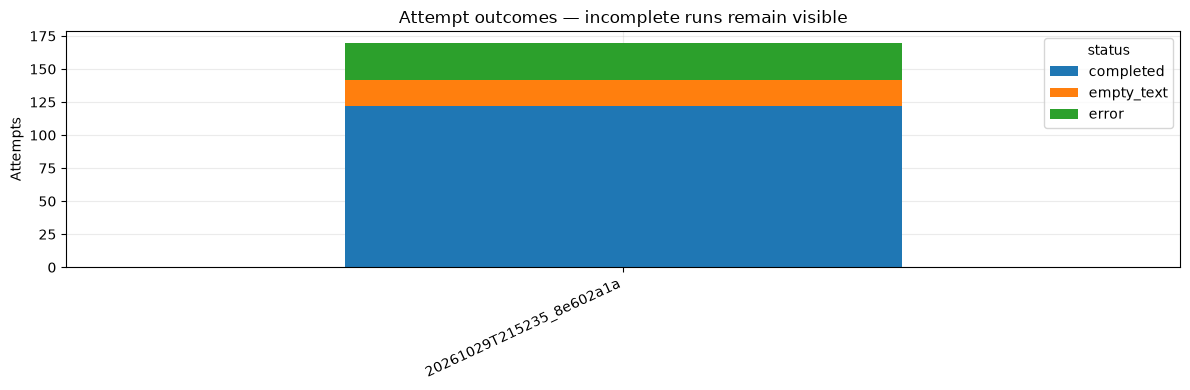

In [4]:
counts = pd.crosstab(attempts["run_id"], attempts["status"])
counts = counts.reindex(selected_runs, fill_value=0)

timing_summary = successful.groupby("run_id")["seconds"].agg(
    successful_attempts="count",
    median_seconds="median",
    mean_seconds="mean",
    fastest_seconds="min",
    slowest_seconds="max",
)

overview = runs.join(counts.add_prefix("status_")).join(timing_summary)
overview["reports_present"] = (
    attempts.groupby("run_id")["report_present"].sum()
)
overview["missing_attempt_reports"] = (
    overview["planned_attempts"] - overview["reports_present"].fillna(0)
)
overview["recorded_processing_minutes"] = (
    attempts.groupby("run_id")["seconds"].sum(min_count=1) / 60
)
overview["whole_run_elapsed_minutes"] = overview["elapsed_seconds"] / 60

display(overview.round(3))

if not counts.empty:
    counts.plot.bar(stacked=True, figsize=(12, 4))
    plt.title("Attempt outcomes — incomplete runs remain visible")
    plt.ylabel("Attempts")
    plt.xlabel("")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### 4. Execution time per CV within each run
Medians use successful repetitions. Red crosses show failed attempts; orange triangles show incomplete attempts’ recorded time.

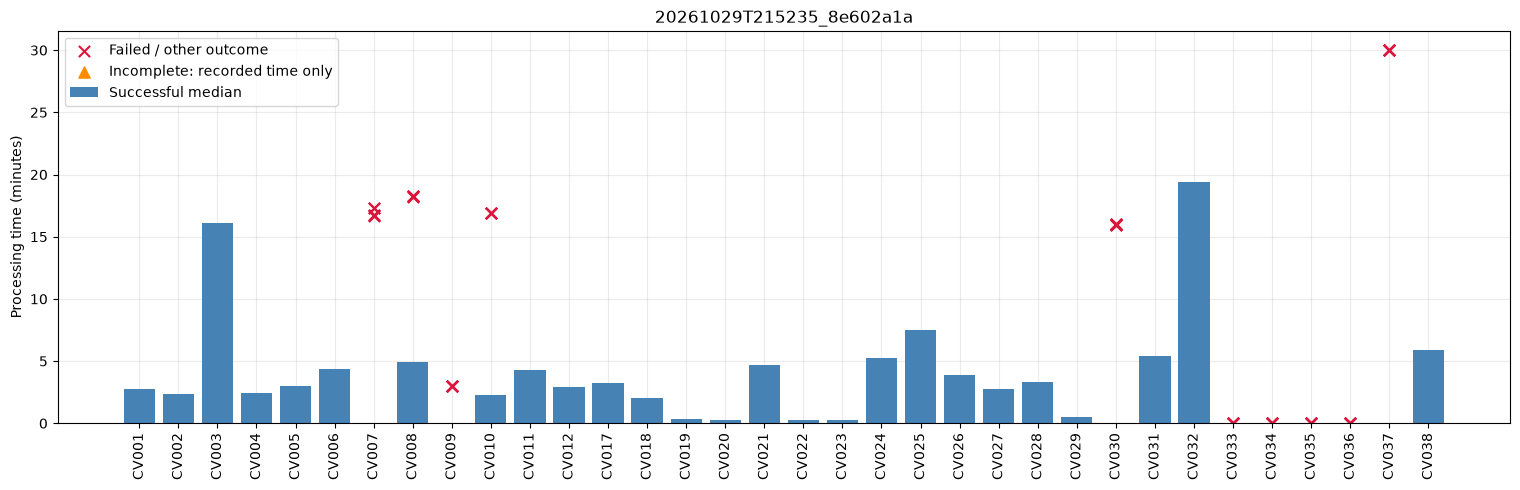

In [5]:
for run_id in selected_runs:
    data = attempts[attempts["run_id"] == run_id]
    if data.empty:
        print(f"{run_id}: no attempt data")
        continue

    cv_order = sorted(data["cv_id"].unique())
    positions = {cv: index for index, cv in enumerate(cv_order)}

    medians = (
        data[data["successful"]]
        .groupby("cv_id")["seconds"]
        .median()
        .reindex(cv_order)
    )

    fig, ax = plt.subplots(figsize=(max(10, len(cv_order) * 0.45), 5))
    ax.bar(
        range(len(cv_order)), medians / 60,
        label="Successful median", color="steelblue",
    )

    for mask, marker, color, label in [
        (~data["successful"] & data["status"].ne("incomplete"),
         "x", "crimson", "Failed / other outcome"),
        (data["status"].eq("incomplete"),
         "^", "darkorange", "Incomplete: recorded time only"),
    ]:
        subset = data[mask]
        ax.scatter(
            subset["cv_id"].map(positions),
            subset["seconds"] / 60,
            marker=marker, color=color, s=65, label=label,
        )

    ax.set_xticks(range(len(cv_order)), cv_order, rotation=90)
    ax.set_ylabel("Processing time (minutes)")
    ax.set_title(run_id)
    ax.legend()
    plt.tight_layout()
    plt.show()

### 5. Stage breakdown per CV
Uses the mean across successful attempts so stacked segments add up to the mean total stage time.

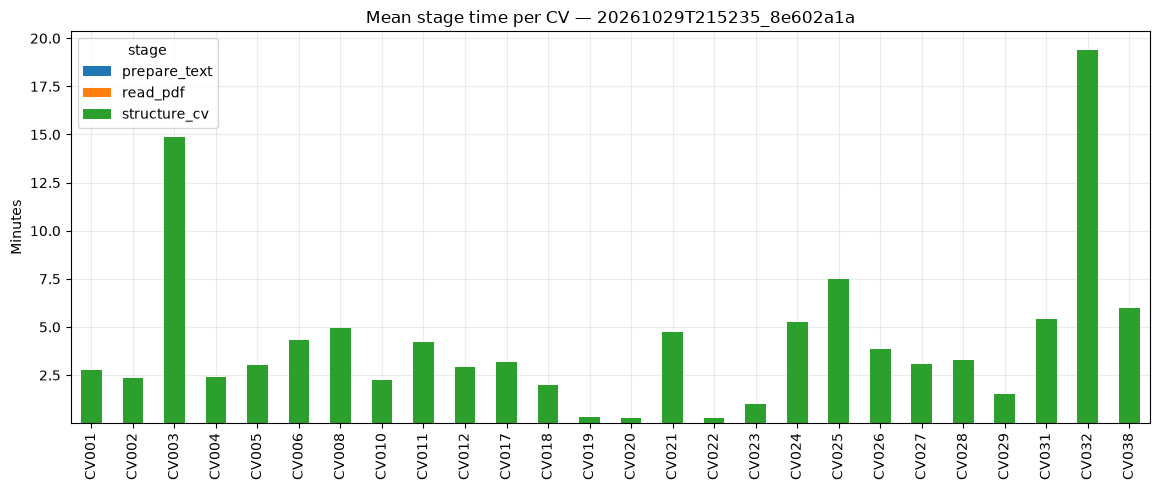

In [6]:
for run_id in selected_runs:
    data = stages[
        stages["run_id"].eq(run_id)
        & stages["attempt_successful"]
        & stages["execution_status"].eq("completed")
    ]

    if data.empty:
        print(f"{run_id}: no successful stage timings")
        continue

    table = data.pivot_table(
        index="cv_id", columns="stage", values="seconds", aggfunc="mean"
    ).sort_index()

    (table / 60).plot.bar(
        stacked=True, figsize=(max(10, len(table) * 0.45), 5)
    )
    plt.title(f"Mean stage time per CV — {run_id}")
    plt.ylabel("Minutes")
    plt.xlabel("")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

### 6. Same CVs across runs
Only includes CVs with at least one successful attempt in every selected run. Different pipelines are still different workloads; check the configuration table when interpreting this comparison.

26 CVs have successful timings in every selected run.


run_id,20261029T215235_8e602a1a
cv_id,
CV001,166.214
CV002,140.661
CV003,967.056
CV004,144.396
CV005,181.089
CV006,260.138
CV008,296.814
CV010,136.136
CV011,258.527


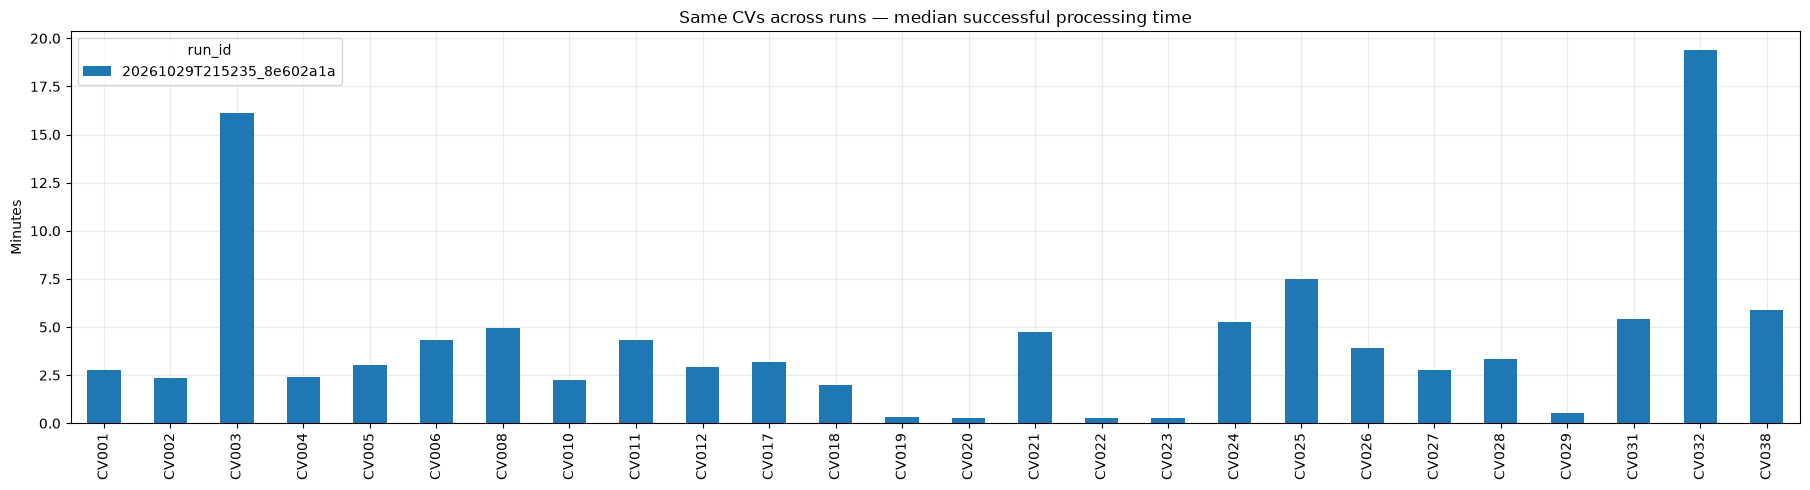

In [7]:
paired = successful.pivot_table(
    index="cv_id", columns="run_id", values="seconds", aggfunc="median"
).reindex(columns=selected_runs)

common_times = paired.dropna()

print(f"{len(common_times)} CVs have successful timings in every selected run.")

if common_times.empty:
    print("No shared successful CVs to compare.")
else:
    display(common_times.round(3))
    (common_times / 60).plot.bar(
        figsize=(max(12, len(common_times) * 0.7), 5)
    )
    plt.title("Same CVs across runs — median successful processing time")
    plt.ylabel("Minutes")
    plt.xlabel("")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

### 7. Speedup against the first selected run
A value of 2 means twice as fast as the baseline. The comparison uses the shared successful CVs from the previous cell.

In [8]:
baseline = selected_runs[0]

if len(selected_runs) < 2 or common_times.empty:
    print("Select at least two runs with shared successful CVs.")
else:
    positive = common_times[(common_times > 0).all(axis=1)]
    speedups = positive.rdiv(positive[baseline], axis=0)
    speedups = speedups.drop(columns=baseline)

    if speedups.empty:
        print("No positive shared timings available.")
    else:
        display(speedups.round(2))
        speedups.plot.bar(figsize=(max(10, len(speedups) * 0.6), 5))
        plt.axhline(1, color="black", linestyle="--", label="Baseline speed")
        plt.title(f"Speedup relative to {baseline}")
        plt.ylabel("Speedup factor — higher is faster")
        plt.xlabel("")
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()

Select at least two runs with shared successful CVs.


### 8. Timing distribution across runs
Uses one median per CV, giving each CV equal weight even when repetition counts differ. CV coverage can differ here.

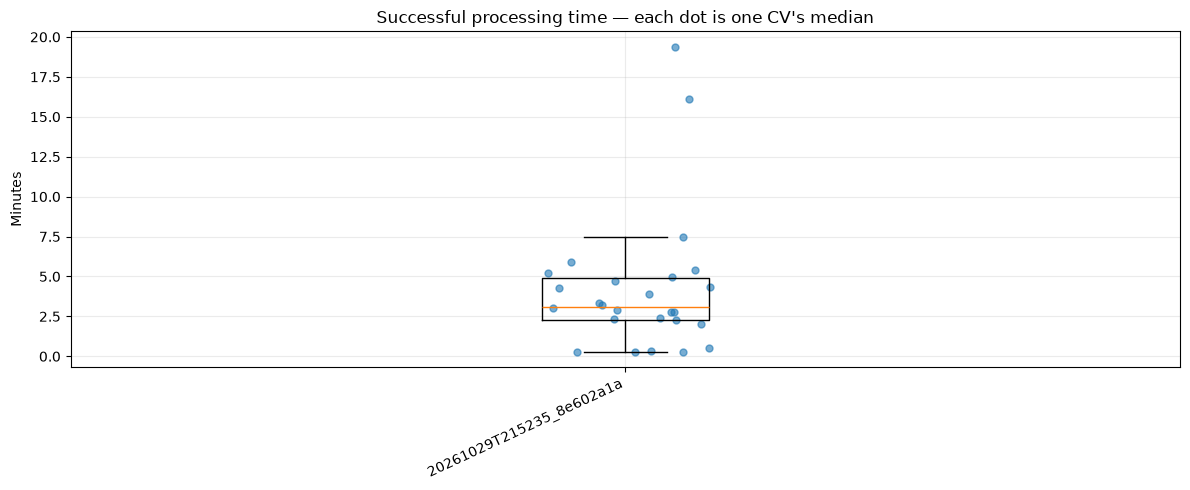

In [9]:
per_cv = successful.groupby(["run_id", "cv_id"])["seconds"].median()

groups = []
labels = []

for run_id in selected_runs:
    if run_id in per_cv.index.get_level_values("run_id"):
        values = per_cv.loc[run_id].dropna().to_numpy() / 60
        if len(values):
            groups.append(values)
            labels.append(run_id)

if not groups:
    print("No successful timings available.")
else:
    fig, ax = plt.subplots()
    ax.boxplot(groups, tick_labels=labels, showfliers=False)

    rng = np.random.default_rng(42)
    for index, values in enumerate(groups, start=1):
        ax.scatter(
            index + rng.uniform(-0.08, 0.08, len(values)),
            values, alpha=0.6, s=25,
        )

    ax.set_title("Successful processing time — each dot is one CV's median")
    ax.set_ylabel("Minutes")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### 9. Variation between repetitions
Useful for checking whether timing is stable. Standard deviation and coefficient of variation require at least two successful repetitions.

repetitions  median_seconds  mean_seconds  \
run_id                   cv_id                                              
20261029T215235_8e602a1a CV023            5          17.761        59.131   
                         CV029            5          32.295        91.416   
                         CV027            5         167.033       184.604   
                         CV003            5         967.056       891.793   
                         CV011            5         258.527       252.246   
                         CV038            5         354.383       359.931   
                         CV019            5          20.862        20.575   
                         CV018            5         120.758       119.751   
                         CV022            5          16.298        16.311   
                         CV001            5         166.214       165.517   
                         CV020            5          17.759        17.786   
                         CV026            5         233.202       233.037   
                         CV028            5         199.044       198.431   
                         CV006            5         260.138       260.029   
                         CV012            5         175.037       175.136   
                         CV004            5         144.396       144.447   
                         CV002            5         140.661       140.603   
                         CV025            5         448.439       448.619   
                         CV005            5         181.089       181.038   
                         CV032            5        1163.571      1163.346   
                         CV031            5         324.625       324.639   
                         CV017            5         192.153       192.117   
                         CV021            5         283.394       283.349   
                         CV024            5         314.358       314.477   

                                std_seconds  min_seconds  max_seconds  \
run_id                   cv_id                                          
20261029T215235_8e602a1a CV023       92.762       17.340      225.068   
                         CV029      132.309       32.063      328.098   
                         CV027       39.389      166.759      255.064   
                         CV003      169.746      588.461      978.464   
                         CV011       13.674      227.839      259.087   
                         CV038       12.405      354.185      382.120   
                         CV019        0.657       19.424       21.008   
                         CV018        2.281      115.671      120.810   
                         CV022        0.234       16.069       16.666   
                         CV001        1.241      163.929      166.676   
                         CV020        0.127       17.606       17.909   
                         CV026        1.305      230.860      234.343   
                         CV028        0.978      197.126      199.226   
                         CV006        0.820      258.962      261.186   
                         CV012        0.338      174.848      175.639   
                         CV004        0.232      144.215      144.787   
                         CV002        0.216      140.334      140.832   
                         CV025        0.607      447.966      449.568   
                         CV005        0.238      180.751      181.366   
                         CV032        1.481     1161.243     1164.755   
                         CV031        0.378      324.042      324.998   
                         CV017        0.207      191.811      192.323   
                         CV021        0.277      283.039      283.742   
                         CV024        0.244      314.280      314.863   

                                variation_percent  
run_id                   cv_id                     
20261029T215235_8e602a1a C

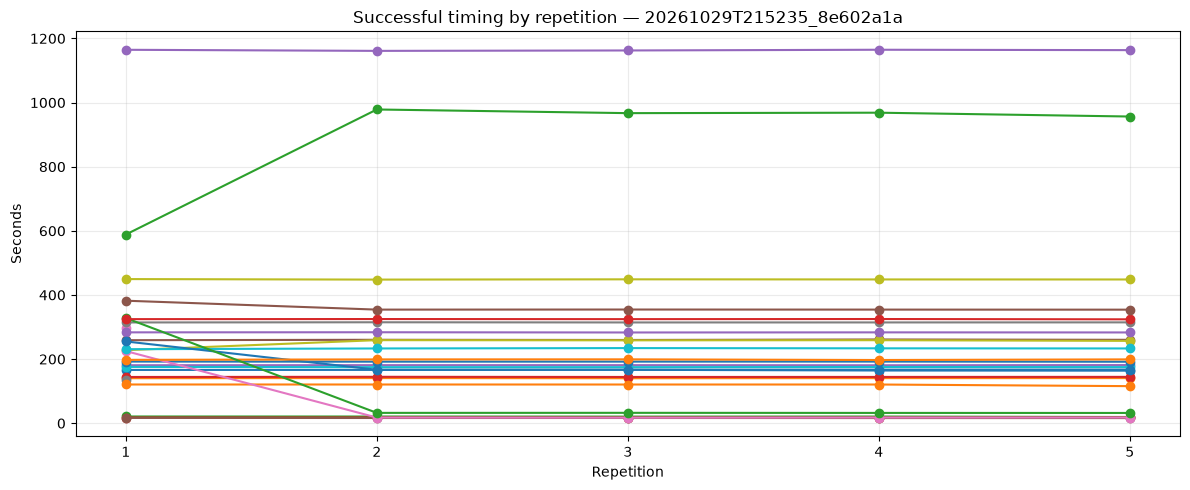

In [10]:
repeat_stats = (
    successful.groupby(["run_id", "cv_id"])["seconds"]
    .agg(
        repetitions="count",
        median_seconds="median",
        mean_seconds="mean",
        std_seconds="std",
        min_seconds="min",
        max_seconds="max",
    )
)

repeat_stats["variation_percent"] = (
    100 * repeat_stats["std_seconds"]
    / repeat_stats["mean_seconds"].replace(0, np.nan)
)

display(
    repeat_stats[repeat_stats["repetitions"] >= 2]
    .sort_values("variation_percent", ascending=False)
    .round(3)
)

for run_id in selected_runs:
    data = successful[successful["run_id"].eq(run_id)]
    if data["repetition"].nunique() < 2:
        continue

    table = data.pivot(
        index="repetition", columns="cv_id", values="seconds"
    )
    table.plot(marker="o", legend=len(table.columns) <= 12)
    plt.title(f"Successful timing by repetition — {run_id}")
    plt.ylabel("Seconds")
    plt.xlabel("Repetition")
    plt.xticks(sorted(data["repetition"].unique()))
    plt.tight_layout()
    plt.show()

### 10. Time spent on successful, failed and incomplete attempts
This exposes the cost of timeouts instead of hiding them behind successful timing averages.

category,Failed / other outcome,Successful
run_id,,
20261029T215235_8e602a1a,470.53,527.08


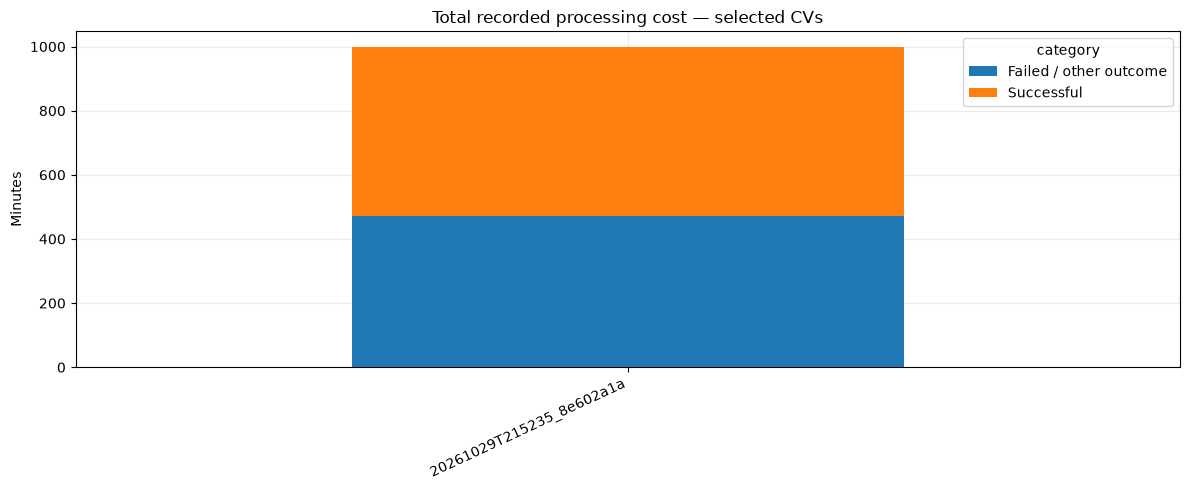

,run_id,cv_id,repetition,stage,seconds,error
92,20261029T215235_8e602a1a,CV007,1,structure_cv,1006.267009,ValueError: Generation did not finish normally...
95,20261029T215235_8e602a1a,CV007,2,structure_cv,1005.675365,ValueError: Generation did not finish normally...
98,20261029T215235_8e602a1a,CV007,3,structure_cv,1038.373315,ValueError: Generation did not finish normally...
101,20261029T215235_8e602a1a,CV007,4,structure_cv,1037.355874,ValueError: Generation did not finish normally...
104,20261029T215235_8e602a1a,CV007,5,structure_cv,998.360141,ValueError: Generation did not finish normally...
110,20261029T215235_8e602a1a,CV008,2,structure_cv,1095.372286,ValueError: Generation did not finish normally...
113,20261029T215235_8e602a1a,CV008,3,structure_cv,1092.996933,ValueError: Generation did not finish normally...
116,20261029T215235_8e602a1a,CV008,4,structure_cv,1096.411132,ValueError: Generation did not finish normally...
119,20261029T215235_8e602a1a,CV008,5,structure_cv,1096.162861,ValueError: Generation did not finish normally...
122,20261029T215235_8e602a1a,CV009,1,structure_cv,181.652128,Ollama returned HTTP 500: Internal Server Error


In [11]:
cost = (
    attempts.assign(
        category=np.where(
            attempts["successful"],
            "Successful",
            np.where(
                attempts["status"].eq("incomplete"),
                "Incomplete: recorded portion",
                "Failed / other outcome",
            ),
        )
    )
    .pivot_table(
        index="run_id", columns="category",
        values="seconds", aggfunc="sum",
    )
    .reindex(selected_runs)
    .fillna(0)
)

if not cost.empty and len(cost.columns):
    display((cost / 60).round(2))
    (cost / 60).plot.bar(stacked=True)
    plt.title("Total recorded processing cost — selected CVs")
    plt.ylabel("Minutes")
    plt.xlabel("")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

failures = stages[stages["execution_status"].eq("error")]
display(failures[
    ["run_id", "cv_id", "repetition", "stage", "seconds", "error"]
])

### 11. LLM generation speed and time breakdown
Only appears when the saved reports contain Ollama timing metrics. This helps distinguish slow token generation from prompt processing or model loading.

,,attempts,median_stage_seconds,median_tokens_per_second,median_output_tokens
run_id,stage,,,,
20261029T215235_8e602a1a,structure_cv,122,192.19,9.82,1828.0


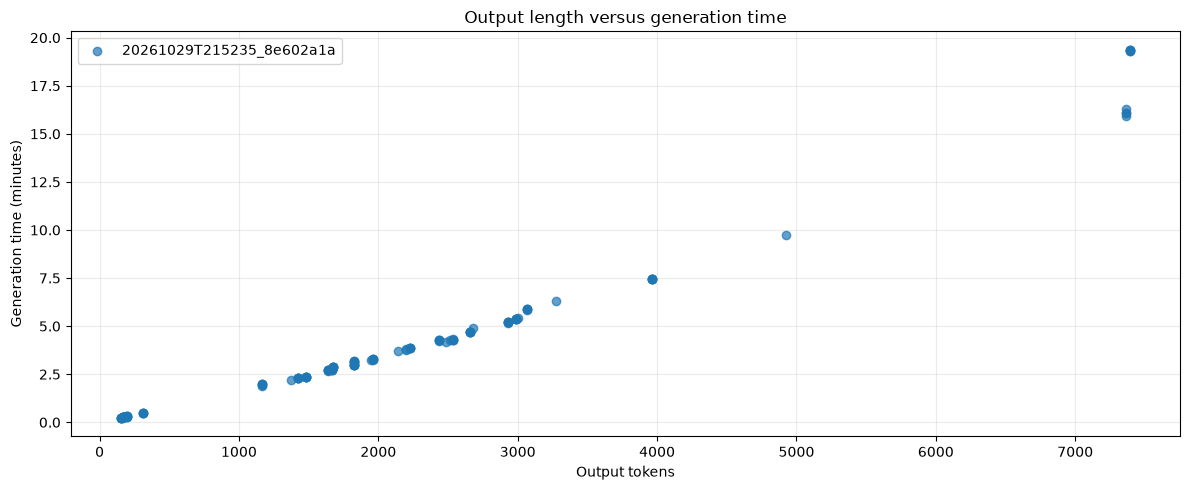

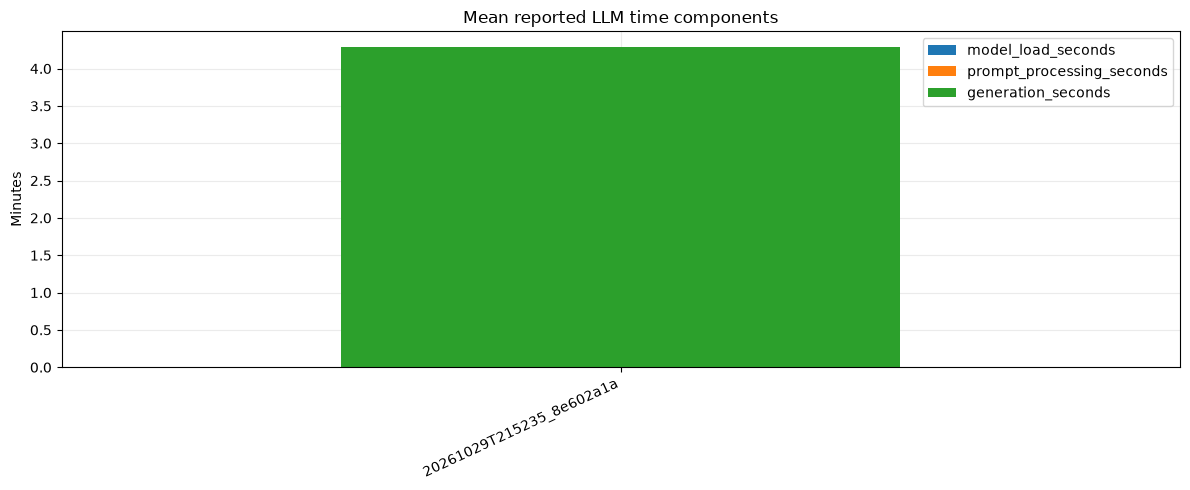

In [12]:
llm = stages[
    stages["execution_status"].eq("completed")
    & stages["generation_seconds"].gt(0)
].copy()

if llm.empty:
    print("No LLM generation timings available.")
else:
    llm["tokens_per_second"] = (
        llm["output_tokens"] / llm["generation_seconds"]
    )

    display(
        llm.groupby(["run_id", "stage"]).agg(
            attempts=("seconds", "count"),
            median_stage_seconds=("seconds", "median"),
            median_tokens_per_second=("tokens_per_second", "median"),
            median_output_tokens=("output_tokens", "median"),
        ).round(2)
    )

    fig, ax = plt.subplots()
    for run_id, data in llm.groupby("run_id"):
        ax.scatter(
            data["output_tokens"], data["generation_seconds"] / 60,
            label=run_id, alpha=0.7,
        )
    ax.set_xlabel("Output tokens")
    ax.set_ylabel("Generation time (minutes)")
    ax.set_title("Output length versus generation time")
    ax.legend()
    plt.tight_layout()
    plt.show()

    components = llm.groupby("run_id")[[
        "model_load_seconds",
        "prompt_processing_seconds",
        "generation_seconds",
    ]].mean()

    (components / 60).plot.bar(stacked=True)
    plt.title("Mean reported LLM time components")
    plt.ylabel("Minutes")
    plt.xlabel("")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()